# GamePulse: Online Gaming Behaviour Analysis

## Project Overview

GamePulse is a data analytics project that explores player behaviour, engagement levels, gaming activity, and in-game purchasing patterns using Python.

The project applies data cleaning, exploratory data analysis (EDA), statistical analysis, K-Means clustering, Isolation Forest anomaly detection, and machine learning classification to investigate patterns in online gaming behaviour.

## Objectives

- Explore player demographics and gaming behaviour.
- Identify patterns associated with different engagement levels.
- Examine relationships between numerical features and purchase behaviour.
- Segment players using K-Means clustering.
- Identify potentially unusual player records using Isolation Forest.
- Evaluate machine learning models for classifying player engagement.
- Translate analytical findings into cautious, data-driven recommendations.

## Dataset

The project uses the *Predict Online Gaming Behavior Dataset* by Rabie El Kharoua, available on Kaggle.

- **Records:** 40,034 players
- **Original features:** 13
- **Target variable:** `EngagementLevel`

The dataset is synthetic. Its findings should therefore be treated as exploratory results rather than direct evidence of real-world gaming behaviour.

## Tools and Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, and Scikit-learn.

1. Initial Data Inspection — Examined the dataset's structure, data types, missing values, duplicates, and descriptive statistics

In [186]:
#IMPORTING LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")



#DATABASE PATH
import os

for folder, subfolders, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(folder, file))

#IMPORTING DATA
data = pd.read_csv("/kaggle/input/datasets/rabieelkharoua/predict-online-gaming-behavior-dataset/online_gaming_behavior_dataset.csv")
print("Dataset loaded successfully!")
print('')

#NUMBER OF ROWS AND COLUMNS IN DATABASE
print('Rows,Columns:', data.shape)
print('Column Names:', data.columns.tolist())

Libraries imported successfully!
/kaggle/input/datasets/rabieelkharoua/predict-online-gaming-behavior-dataset/online_gaming_behavior_dataset.csv
Dataset loaded successfully!

Rows,Columns: (40034, 13)
Column Names: ['PlayerID', 'Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked', 'EngagementLevel']


2. Data Cleaning & Preparation - Validated data quality and investigated potential inconsistencies in player records.

In [50]:
#DATA CLEANING BY FINDING NULL AND DUPLICATE VALUES

print("Missing values per column:")
print(data.isnull().sum())
print('')

print("Number of rows duplicated:")
print(data.duplicated().sum())
print('')



print("Duplicated PlayerIDs:")
print(data['PlayerID'].duplicated().sum())
print('')

print("Unique PlayerIDs:")
print(data['PlayerID'].nunique())
print('')

Missing values per column:
PlayerID                     0
Age                          0
Gender                       0
Location                     0
GameGenre                    0
PlayTimeHours                0
InGamePurchases              0
GameDifficulty               0
SessionsPerWeek              0
AvgSessionDurationMinutes    0
PlayerLevel                  0
AchievementsUnlocked         0
EngagementLevel              0
dtype: int64

Number of rows duplicated:
0

Duplicated PlayerIDs:
0

Unique PlayerIDs:
40034



In [78]:
#CATEGORICAL COLUMNS BY NUMBERS

category_columns = ["Gender","Location","GameGenre","InGamePurchases","GameDifficulty","EngagementLevel"]

for x in category_columns:
    print('Count:')
    print(data[x].value_counts())
    print('')
    print('%distribution:')
    print(round((data[x].value_counts()/data[x].shape[0])*100,2))
    print('Number of Unique Categories',data[x].nunique())
    print('')
    print('')

Count:
Gender
Male      23959
Female    16075
Name: count, dtype: int64

%distribution:
Gender
Male      59.85
Female    40.15
Name: count, dtype: float64
Number of Unique Categories 2


Count:
Location
USA       16000
Europe    12004
Asia       8095
Other      3935
Name: count, dtype: int64

%distribution:
Location
USA       39.97
Europe    29.98
Asia      20.22
Other      9.83
Name: count, dtype: float64
Number of Unique Categories 4


Count:
GameGenre
Sports        8048
Action        8039
Strategy      8012
Simulation    7983
RPG           7952
Name: count, dtype: int64

%distribution:
GameGenre
Sports        20.10
Action        20.08
Strategy      20.01
Simulation    19.94
RPG           19.86
Name: count, dtype: float64
Number of Unique Categories 5


Count:
InGamePurchases
0    31993
1     8041
Name: count, dtype: int64

%distribution:
InGamePurchases
0    79.91
1    20.09
Name: count, dtype: float64
Number of Unique Categories 2


Count:
GameDifficulty
Easy      20015
Medium    1

In [92]:
#BASIC INFORMATION ABOUT DATABASE

print('Column Names:', data.columns.tolist())
print('')
print('')

print(data.dtypes)
print('')
print('')

data.info()
print('')
print('')

print(data.describe().T)
print('')
print('')

Column Names: ['PlayerID', 'Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked', 'EngagementLevel']


PlayerID                       int64
Age                            int64
Gender                        object
Location                      object
GameGenre                     object
PlayTimeHours                float64
InGamePurchases                int64
GameDifficulty                object
SessionsPerWeek                int64
AvgSessionDurationMinutes      int64
PlayerLevel                    int64
AchievementsUnlocked           int64
EngagementLevel               object
dtype: object


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int

In [100]:
print('MIN:')
print(data[["Age","PlayTimeHours","SessionsPerWeek","AvgSessionDurationMinutes","PlayerLevel","AchievementsUnlocked"
]].min())
print('')

print('MAX:')
print(data[["Age","PlayTimeHours","SessionsPerWeek","AvgSessionDurationMinutes","PlayerLevel","AchievementsUnlocked"
]].max())

MIN:
Age                          15.000000
PlayTimeHours                 0.000115
SessionsPerWeek               0.000000
AvgSessionDurationMinutes    10.000000
PlayerLevel                   1.000000
AchievementsUnlocked          0.000000
dtype: float64

MAX:
Age                           49.000000
PlayTimeHours                 23.999592
SessionsPerWeek               19.000000
AvgSessionDurationMinutes    179.000000
PlayerLevel                   99.000000
AchievementsUnlocked          49.000000
dtype: float64


In [103]:
categorical_columns = [
    "Gender",
    "Location",
    "GameGenre",
    "GameDifficulty",
    "EngagementLevel"
]

for column in categorical_columns:
    print(data[column].unique())
    print('')

['Male' 'Female']

['Other' 'USA' 'Europe' 'Asia']

['Strategy' 'Sports' 'Action' 'RPG' 'Simulation']

['Medium' 'Easy' 'Hard']

['Medium' 'High' 'Low']



In [30]:
#INGAMEPURCHASES

print('Unique Categories:',data["InGamePurchases"].unique())
print('Unique Categories By Numbers:',data["InGamePurchases"].value_counts())
print(data["InGamePurchases"].isin([0, 1]).all())
print('-'*50)

Purchase_Percentage = data.query("InGamePurchases == 1").shape[0]/data.shape[0]
print('Players With InGamePurchases:',round(Purchase_Percentage*100,2),'%')

Unique Categories: [0 1]
Unique Categories By Numbers: InGamePurchases
0    31993
1     8041
Name: count, dtype: int64
True
--------------------------------------------------
Players With InGamePurchases: 20.09 %


In [32]:
#BLANK STRINGS AND VALUES WITH EXTRA SPACINGS

categorical_columns = [
    "Gender",
    "Location",
    "GameGenre",
    "GameDifficulty",
    "EngagementLevel"
]

for column in categorical_columns:
    print(
        "Blank strings:",
        data[column].astype(str).str.strip().eq("").sum()
    )
    print(
        "Values with extra surrounding spaces:",
        data[column].astype(str).ne(
            data[column].astype(str).str.strip()
        ).sum()
    )
    print('')

Blank strings: 0
Values with extra surrounding spaces: 0

Blank strings: 0
Values with extra surrounding spaces: 0

Blank strings: 0
Values with extra surrounding spaces: 0

Blank strings: 0
Values with extra surrounding spaces: 0

Blank strings: 0
Values with extra surrounding spaces: 0



In [47]:
#NEGETIVE VALUE AND NULL VALUES IN COLUMNS

numerical_columns = [
    "Age",
    "PlayTimeHours",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "PlayerLevel",
    "AchievementsUnlocked"
]

for c in numerical_columns:
    print("No of Negtive Values:",(data[c]<0).sum())
    print('No of Blank Values:',data[c].isnull().sum())
    print('')

No of Negtive Values: 0
No of Blank Values: 0

No of Negtive Values: 0
No of Blank Values: 0

No of Negtive Values: 0
No of Blank Values: 0

No of Negtive Values: 0
No of Blank Values: 0

No of Negtive Values: 0
No of Blank Values: 0

No of Negtive Values: 0
No of Blank Values: 0



In [48]:
print("Players with zero sessions per week:",
      (data["SessionsPerWeek"] == 0).sum())

print("\nPlayers with zero playtime:",
      (data["PlayTimeHours"] == 0).sum())

print("\nPlayers with zero achievements:",
      (data["AchievementsUnlocked"] == 0).sum())

print("\nPlayers at minimum level:",
      (data["PlayerLevel"] == 1).sum())

Players with zero sessions per week: 1967

Players with zero playtime: 0

Players with zero achievements: 810

Players at minimum level: 408


In [55]:
zero_sessions = data.query("SessionsPerWeek == 0")

print("Total zero-session players:", zero_sessions.shape[0])

print("\nPlaytime statistics:")
print(zero_sessions["PlayTimeHours"].describe())

print("\nAverage session duration:")
print(zero_sessions["AvgSessionDurationMinutes"].mean())

print("\nEngagement distribution:")
print(zero_sessions["EngagementLevel"].value_counts())

Total zero-session players: 1967

Playtime statistics:
count    1967.000000
mean       12.026800
std         6.852776
min         0.013024
25%         5.954186
50%        11.893624
75%        17.930734
max        23.995123
Name: PlayTimeHours, dtype: float64

Average session duration:
95.62480935434672

Engagement distribution:
EngagementLevel
Low       1842
High        70
Medium      55
Name: count, dtype: int64


In [113]:
data.groupby(data["SessionsPerWeek"] == 0)[
    ["PlayTimeHours", "AvgSessionDurationMinutes", "PlayerLevel"]
].mean()

,PlayTimeHours,AvgSessionDurationMinutes,PlayerLevel
SessionsPerWeek,,,
False,12.02424,94.749232,49.661833
True,12.02680,95.624809,49.534316


In [58]:
print(data["EngagementLevel"].value_counts())

print("\nEngagement percentages:")
print(
    (data["EngagementLevel"].value_counts(normalize=True) * 100)
    .round(2)
)

EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64

Engagement percentages:
EngagementLevel
Medium    48.39
High      25.82
Low       25.79
Name: proportion, dtype: float64


In [59]:
zero_sessions = data.query("SessionsPerWeek == 0")

print("Total zero-session players:", len(zero_sessions))

print("\nSession duration distribution:")
print(zero_sessions["AvgSessionDurationMinutes"].value_counts().head(10))

print("\nEngagement vs zero sessions:")
print(
    pd.crosstab(
        zero_sessions["EngagementLevel"],
        zero_sessions["SessionsPerWeek"]
    )
)

Total zero-session players: 1967

Session duration distribution:
AvgSessionDurationMinutes
140    22
92     22
29     21
59     21
168    20
116    19
108    19
124    19
107    18
30     18
Name: count, dtype: int64

Engagement vs zero sessions:
SessionsPerWeek     0
EngagementLevel      
High               70
Low              1842
Medium             55


In [112]:
pd.crosstab(
    data["SessionsPerWeek"],
    data["EngagementLevel"],
    normalize="index"
).round(3) * 100

EngagementLevel,High,Low,Medium
SessionsPerWeek,,,
0,3.6,93.6,2.8
1,3.1,91.3,5.6
2,3.5,68.6,27.8
3,3.2,45.4,51.4
4,3.5,32.9,63.7
5,3.2,26.9,69.9
6,2.8,22.4,74.8
7,2.9,17.7,79.3
8,7.8,16.4,75.8


In [115]:
data.groupby("EngagementLevel")[
    ["SessionsPerWeek", "PlayTimeHours", "AvgSessionDurationMinutes"]
].mean().round(2)

,SessionsPerWeek,PlayTimeHours,AvgSessionDurationMinutes
EngagementLevel,,,
High,14.25,12.07,131.92
Low,4.53,12.10,66.88
Medium,9.55,11.96,89.86


In [64]:
data.groupby("EngagementLevel")["AvgSessionDurationMinutes"].mean()

EngagementLevel
High      131.921827
Low        66.882119
Medium     89.856405
Name: AvgSessionDurationMinutes, dtype: float64

In [67]:
data_clean = data.copy()

print("Original dataset shape:", data.shape)
print("Working dataset shape:", data_clean.shape)

print("\nMissing values:", data_clean.isnull().sum().sum())
print("Duplicate rows:", data_clean.duplicated().sum())
print("Duplicate PlayerIDs:", data_clean["PlayerID"].duplicated().sum())

Original dataset shape: (40034, 13)
Working dataset shape: (40034, 13)

Missing values: 0
Duplicate rows: 0
Duplicate PlayerIDs: 0


3. Exploratory Data Analysis (EDA) - Visualised player demographics, gaming behaviour, engagement levels, and purchase patterns.

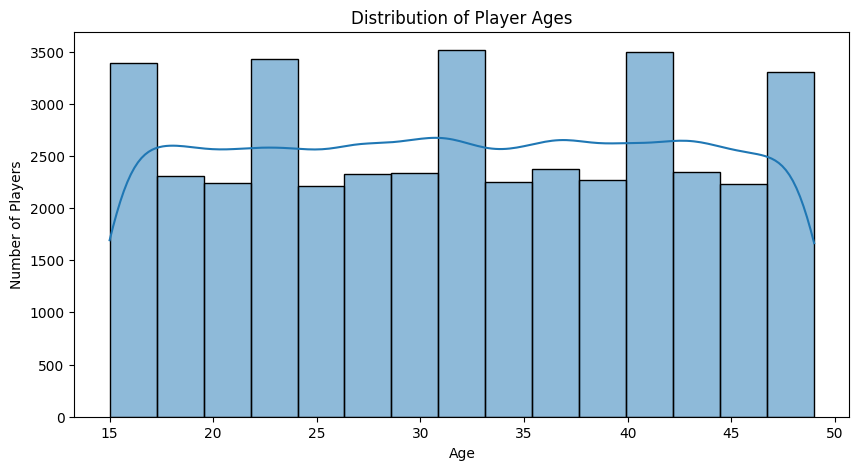

In [71]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=data_clean,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Distribution of Player Ages")
plt.xlabel("Age")
plt.ylabel("Number of Players")

plt.show()

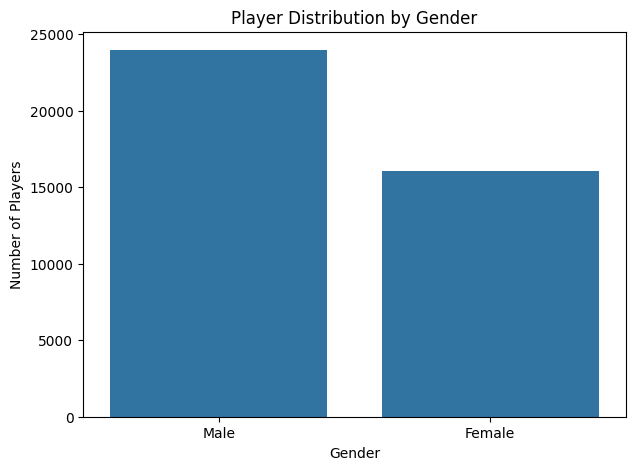

In [72]:
plt.figure(figsize=(7, 5))

sns.countplot(data=data_clean, x="Gender")

plt.title("Player Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Players")

plt.show()

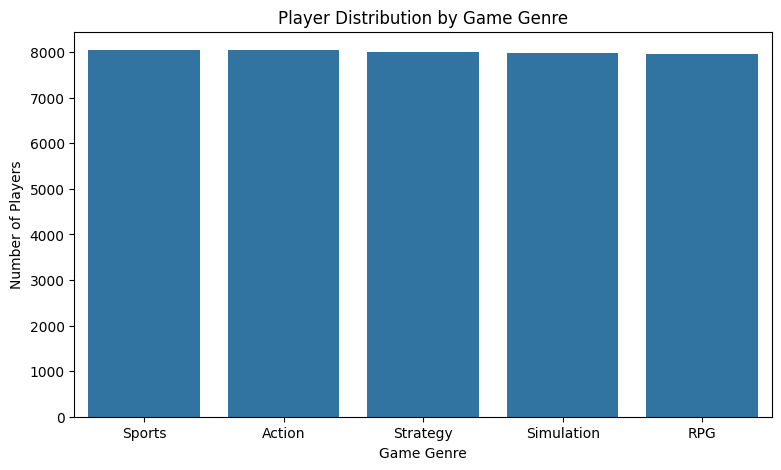

In [76]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=data_clean,
    x="GameGenre",
    order=data_clean["GameGenre"].value_counts().index
)

plt.title("Player Distribution by Game Genre")
plt.xlabel("Game Genre")
plt.ylabel("Number of Players")

plt.show()

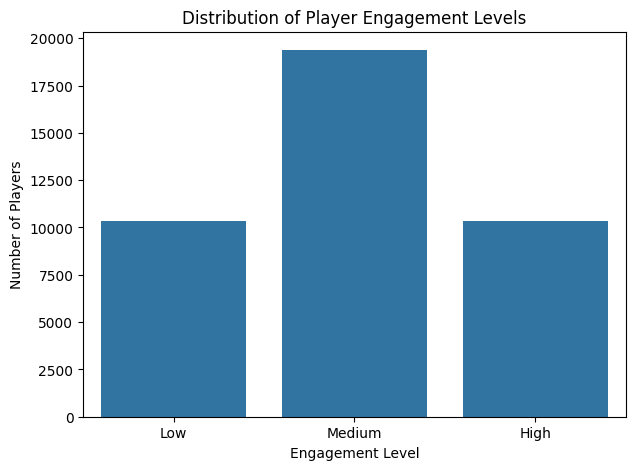

In [77]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=data_clean,
    x="EngagementLevel",
    order=["Low", "Medium", "High"]
)

plt.title("Distribution of Player Engagement Levels")
plt.xlabel("Engagement Level")
plt.ylabel("Number of Players")

plt.show()

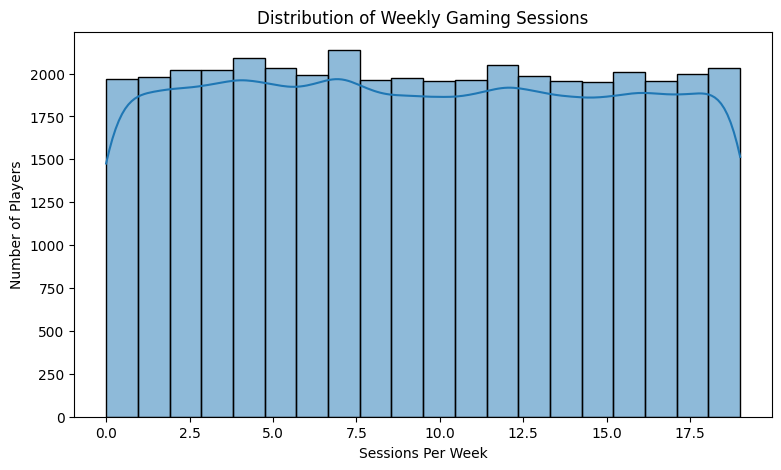

In [78]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=data_clean,
    x="SessionsPerWeek",
    bins=20,
    kde=True
)

plt.title("Distribution of Weekly Gaming Sessions")
plt.xlabel("Sessions Per Week")
plt.ylabel("Number of Players")

plt.show()

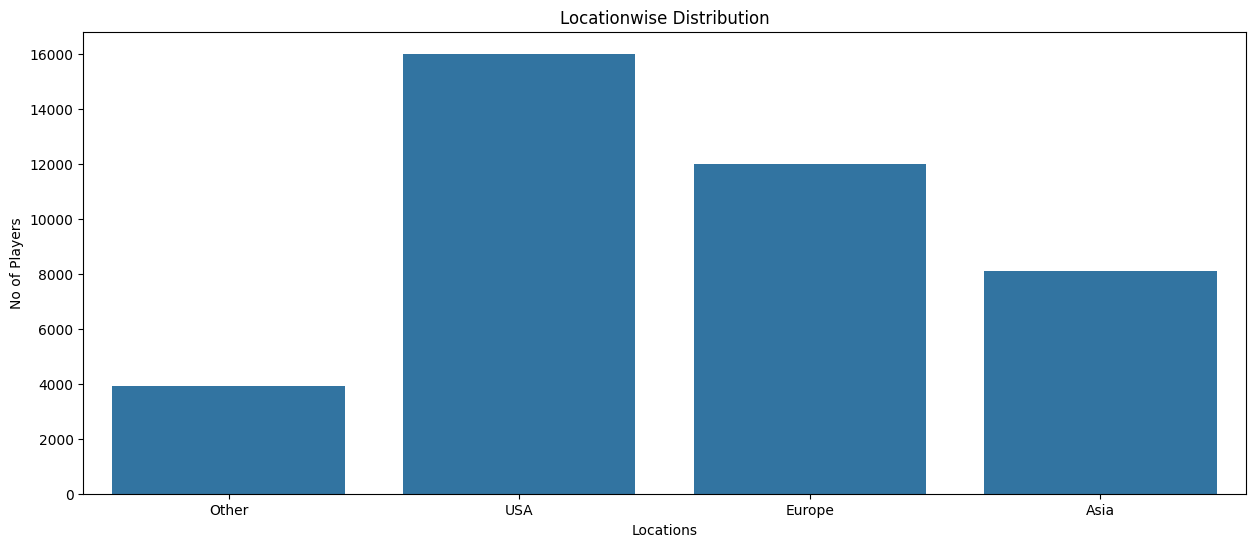

In [87]:
plt.figure(figsize=(15,6))

sns.countplot(
    data = data_clean,
    x = "Location"
)

plt.title("Locationwise Distribution")
plt.xlabel("Locations")
plt.ylabel("No of Players")

plt.show()

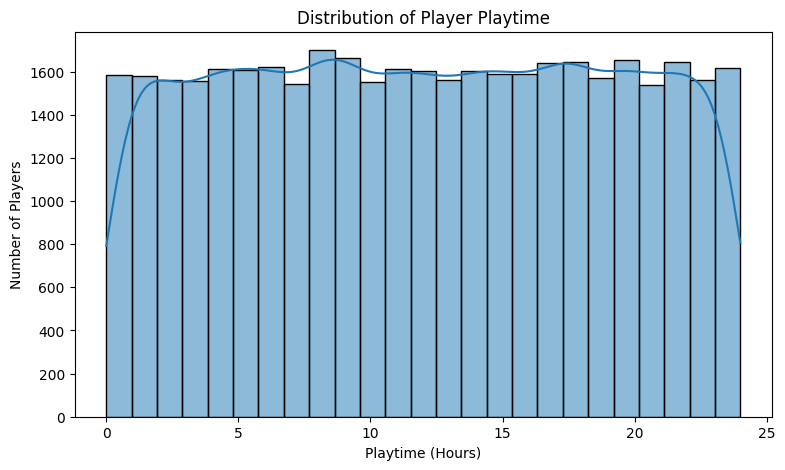

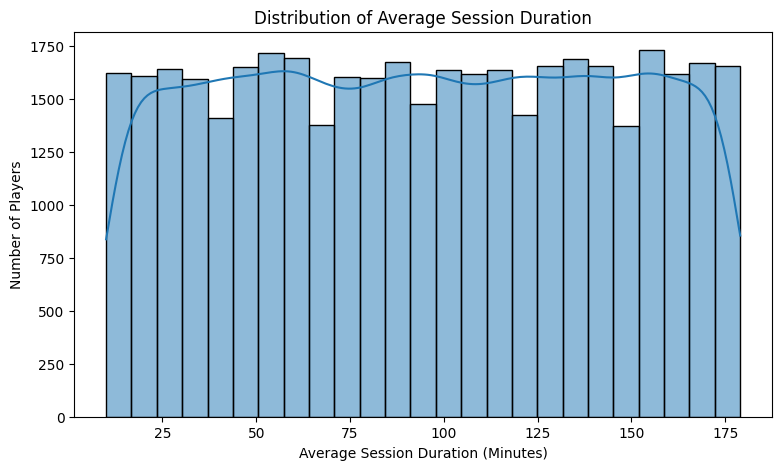

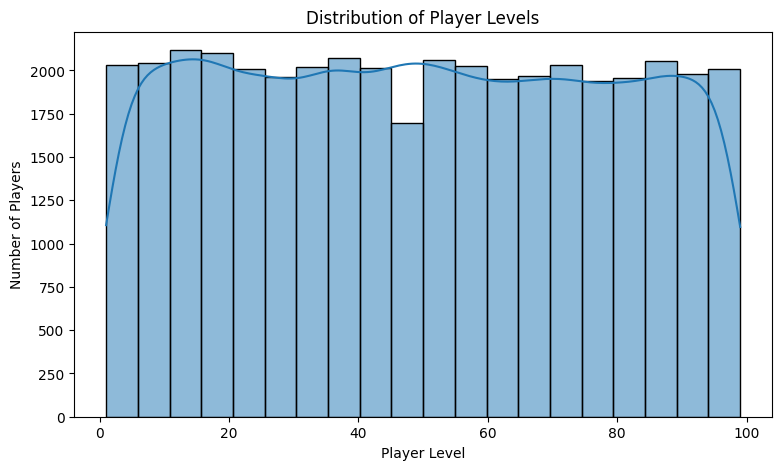

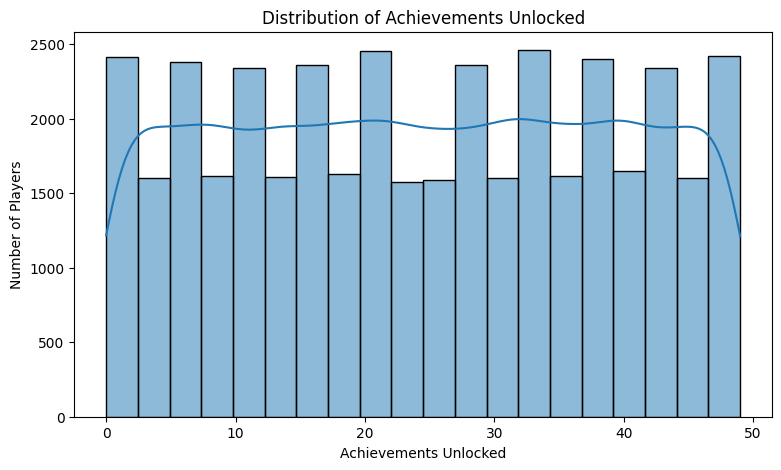

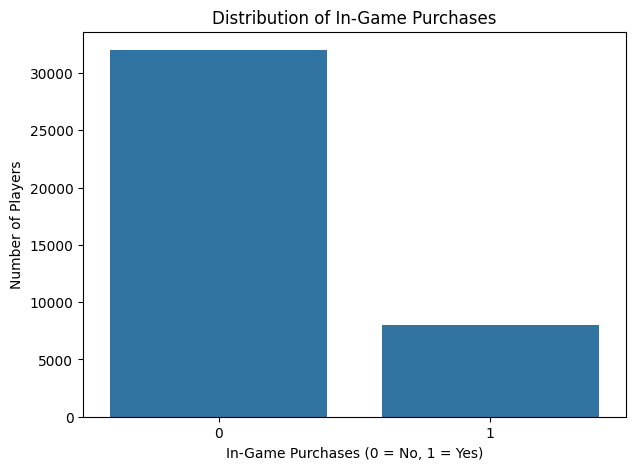

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Playtime distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=data_clean, x="PlayTimeHours", bins=25, kde=True)
plt.title("Distribution of Player Playtime")
plt.xlabel("Playtime (Hours)")
plt.ylabel("Number of Players")
plt.show()

# 2. Average session duration
plt.figure(figsize=(9, 5))
sns.histplot(
    data=data_clean,
    x="AvgSessionDurationMinutes",
    bins=25,
    kde=True
)
plt.title("Distribution of Average Session Duration")
plt.xlabel("Average Session Duration (Minutes)")
plt.ylabel("Number of Players")
plt.show()

# 3. Player level distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=data_clean, x="PlayerLevel", bins=20, kde=True)
plt.title("Distribution of Player Levels")
plt.xlabel("Player Level")
plt.ylabel("Number of Players")
plt.show()

# 4. Achievements unlocked
plt.figure(figsize=(9, 5))
sns.histplot(
    data=data_clean,
    x="AchievementsUnlocked",
    bins=20,
    kde=True
)
plt.title("Distribution of Achievements Unlocked")
plt.xlabel("Achievements Unlocked")
plt.ylabel("Number of Players")
plt.show()

# 5. In-game purchases
plt.figure(figsize=(7, 5))
sns.countplot(
    data=data_clean,
    x="InGamePurchases",
    order=[0, 1]
)
plt.title("Distribution of In-Game Purchases")
plt.xlabel("In-Game Purchases (0 = No, 1 = Yes)")
plt.ylabel("Number of Players")
plt.show()

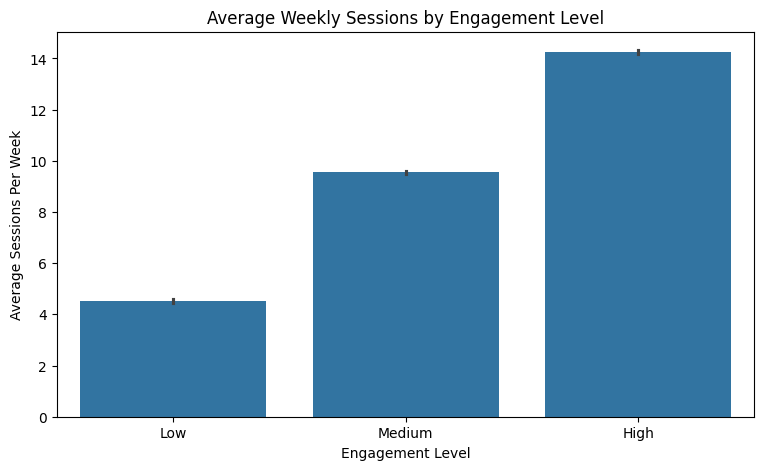

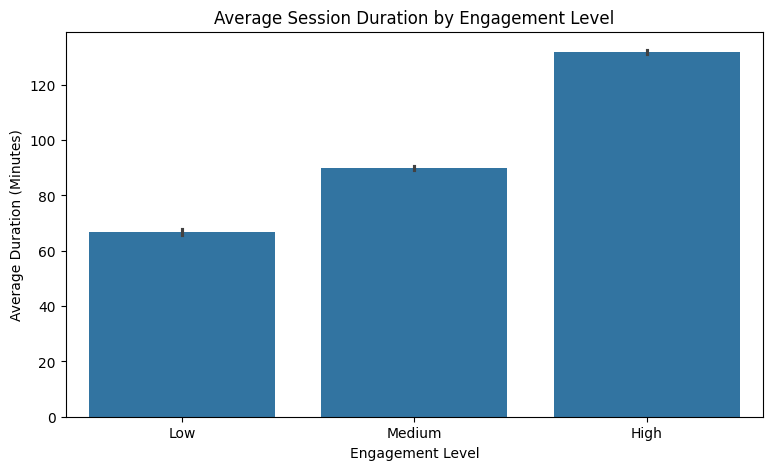

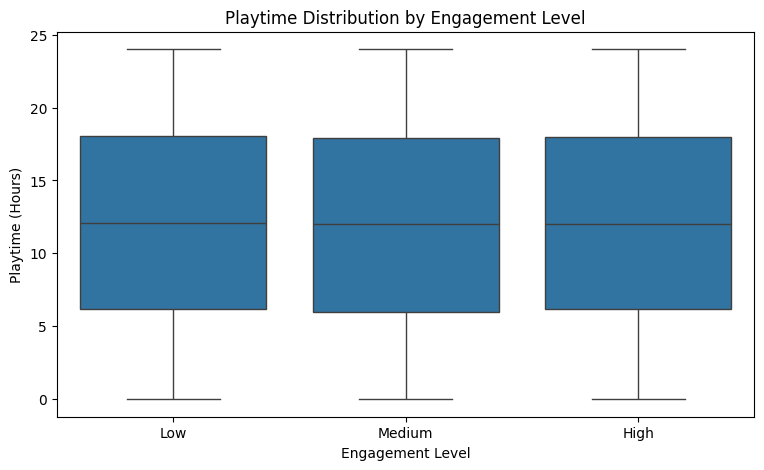

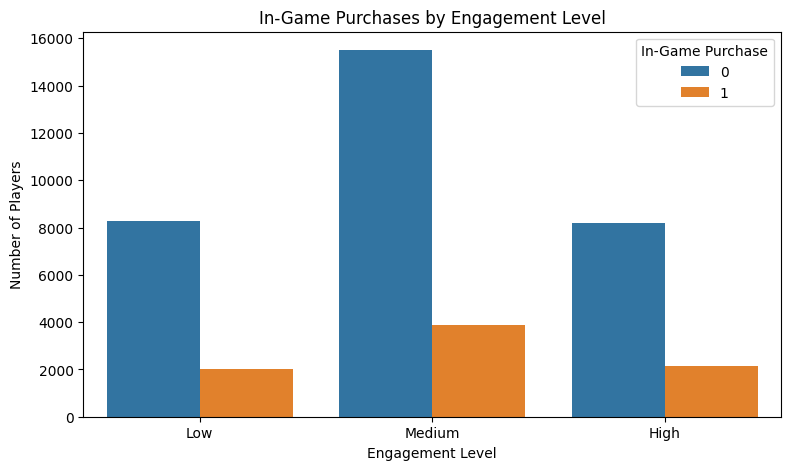

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Weekly sessions vs engagement
plt.figure(figsize=(9, 5))
sns.barplot(
    data=data_clean,
    x="EngagementLevel",
    y="SessionsPerWeek",
    order=["Low", "Medium", "High"]
)
plt.title("Average Weekly Sessions by Engagement Level")
plt.xlabel("Engagement Level")
plt.ylabel("Average Sessions Per Week")
plt.show()

# 2. Average session duration vs engagement
plt.figure(figsize=(9, 5))
sns.barplot(
    data=data_clean,
    x="EngagementLevel",
    y="AvgSessionDurationMinutes",
    order=["Low", "Medium", "High"]
)
plt.title("Average Session Duration by Engagement Level")
plt.xlabel("Engagement Level")
plt.ylabel("Average Duration (Minutes)")
plt.show()

# 3. Playtime vs engagement
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=data_clean,
    x="EngagementLevel",
    y="PlayTimeHours",
    order=["Low", "Medium", "High"]
)
plt.title("Playtime Distribution by Engagement Level")
plt.xlabel("Engagement Level")
plt.ylabel("Playtime (Hours)")
plt.show()

# 4. In-game purchases vs engagement
plt.figure(figsize=(9, 5))
sns.countplot(
    data=data_clean,
    x="EngagementLevel",
    hue="InGamePurchases",
    order=["Low", "Medium", "High"]
)
plt.title("In-Game Purchases by Engagement Level")
plt.xlabel("Engagement Level")
plt.ylabel("Number of Players")
plt.legend(title="In-Game Purchase")
plt.show()

4. Statistical Analysis - Analysed numerical relationships and tested differences in playtime across engagement groups.

In [94]:
numerical_columns = [
    "Age",
    "PlayTimeHours",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "PlayerLevel",
    "AchievementsUnlocked"
]

descriptive_stats = data_clean[numerical_columns].describe().T

print(descriptive_stats[["mean", "50%", "std", "min", "max"]].round(2))

                            mean    50%    std   min    max
Age                        31.99  32.00  10.04  15.0   49.0
PlayTimeHours              12.02  12.01   6.91   0.0   24.0
SessionsPerWeek             9.47   9.00   5.76   0.0   19.0
AvgSessionDurationMinutes  94.79  95.00  49.01  10.0  179.0
PlayerLevel                49.66  49.00  28.59   1.0   99.0
AchievementsUnlocked       24.53  25.00  14.43   0.0   49.0


                            Age  PlayTimeHours  SessionsPerWeek  \
Age                        1.00           0.00             0.01   
PlayTimeHours              0.00           1.00            -0.00   
SessionsPerWeek            0.01          -0.00             1.00   
AvgSessionDurationMinutes -0.00          -0.00            -0.00   
PlayerLevel                0.00          -0.01             0.00   
AchievementsUnlocked      -0.00           0.00             0.00   

                           AvgSessionDurationMinutes  PlayerLevel  \
Age                                             -0.0         0.00   
PlayTimeHours                                   -0.0        -0.01   
SessionsPerWeek                                 -0.0         0.00   
AvgSessionDurationMinutes                        1.0         0.00   
PlayerLevel                                      0.0         1.00   
AchievementsUnlocked                            -0.0         0.01   

                           AchievementsUnlocke

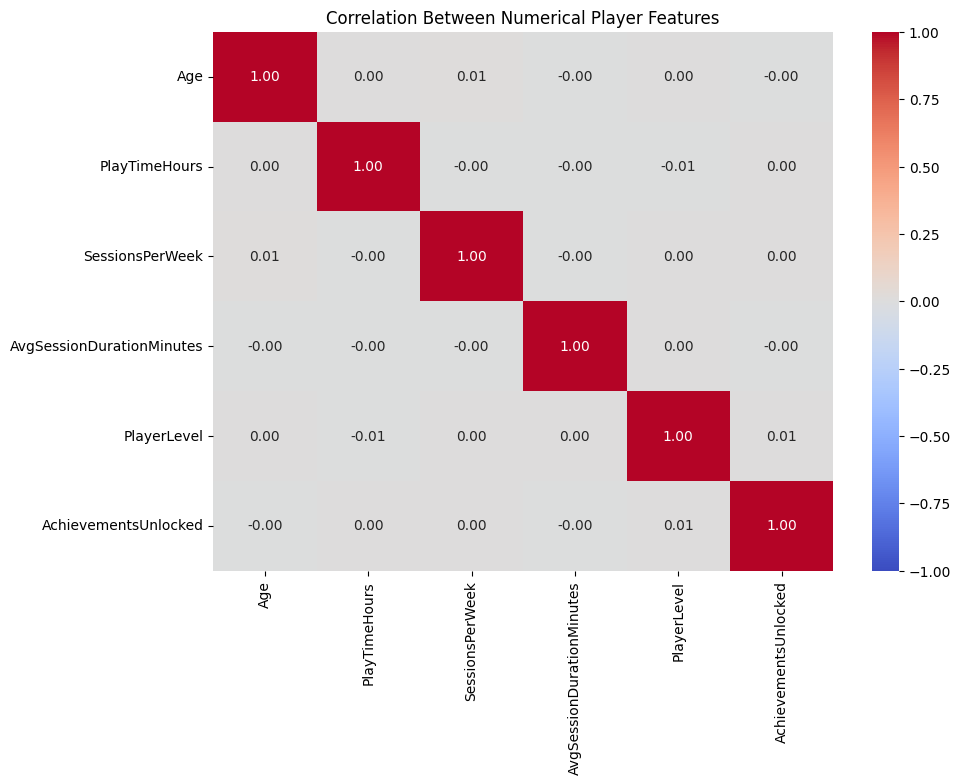

In [101]:
numerical_columns = [
    "Age",
    "PlayTimeHours",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "PlayerLevel",
    "AchievementsUnlocked"
]

correlation_matrix = data_clean[numerical_columns].corr()

print(correlation_matrix.round(2))
print("-"*100)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Numerical Player Features")
plt.show()

In [117]:
engagement_summary = (
    data_clean.groupby("EngagementLevel")[
        ["SessionsPerWeek", "AvgSessionDurationMinutes", "PlayTimeHours"]
    ]
    .agg(["mean", "median", "std"])
    .round(2)
)

print(engagement_summary)

                SessionsPerWeek              AvgSessionDurationMinutes         \
                           mean median   std                      mean median   
EngagementLevel                                                                 
High                      14.25   15.0  3.91                    131.92  137.0   
Low                        4.53    3.0  4.86                     66.88   53.0   
Medium                     9.55    9.0  4.76                     89.86   84.0   

                       PlayTimeHours               
                   std          mean median   std  
EngagementLevel                                    
High             34.07         12.07  11.98  6.91  
Low              48.59         12.10  12.07  6.89  
Medium           43.72         11.96  11.99  6.93  


In [127]:
x = pd.crosstab(
    data["EngagementLevel"],
    data["InGamePurchases"],
    normalize="index"
)*100
print(round(x,2))

InGamePurchases      0      1
EngagementLevel              
High             79.35  20.65
Low              80.27  19.73
Medium           80.02  19.98


In [131]:

from scipy.stats import kruskal

# Separate playtime values for each engagement group
low = data_clean.loc[
    data_clean["EngagementLevel"] == "Low", "PlayTimeHours"
]

medium = data_clean.loc[
    data_clean["EngagementLevel"] == "Medium", "PlayTimeHours"
]

high = data_clean.loc[
    data_clean["EngagementLevel"] == "High", "PlayTimeHours"
]

# Perform Kruskal-Wallis test
statistic, p_value = kruskal(low, medium, high)

print("Kruskal-Wallis H-statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Statistically significant difference")
else:
    print("Result: No statistically significant difference")


Kruskal-Wallis H-statistic: 3.6602690404542955
P-value: 0.16039199035693022
Result: No statistically significant difference


5. Player Segmentation Using K-Means - Grouped players based on similarities in their gaming behaviour and progression.

In [132]:
clustering_features = [
    "PlayTimeHours",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "PlayerLevel",
    "AchievementsUnlocked"
]

X = data_clean[clustering_features].copy()

print("Clustering dataset shape:", X.shape)
print("\nSelected features:")
print(X.columns.tolist())

print("\nFirst 5 rows:")
print(X.head())


Clustering dataset shape: (40034, 5)

Selected features:
['PlayTimeHours', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked']

First 5 rows:
   PlayTimeHours  SessionsPerWeek  AvgSessionDurationMinutes  PlayerLevel  \
0      16.271119                6                        108           79   
1       5.525961                5                        144           11   
2       8.223755               16                        142           35   
3       5.265351                9                         85           57   
4      15.531945                2                        131           95   

   AchievementsUnlocked  
0                    25  
1                    10  
2                    41  
3                    47  
4                    37  


In [133]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardise all five features
X_scaled = scaler.fit_transform(X)

print("Scaled dataset shape:", X_scaled.shape)

print("\nFirst 5 scaled rows:")
print(X_scaled[:5])


Scaled dataset shape: (40034, 5)

First 5 scaled rows:
[[ 0.61417626 -0.60236257  0.2694867   1.02645899  0.0328139 ]
 [-0.93981568 -0.77586539  1.00401924 -1.35215957 -1.00664781]
 [-0.54965389  1.13266561  0.96321188 -0.51264714  1.14157306]
 [-0.97750578 -0.08185412 -0.19979799  0.25690592  1.55735775]
 [ 0.507275   -1.29637384  0.73877138  1.58613394  0.86438327]]


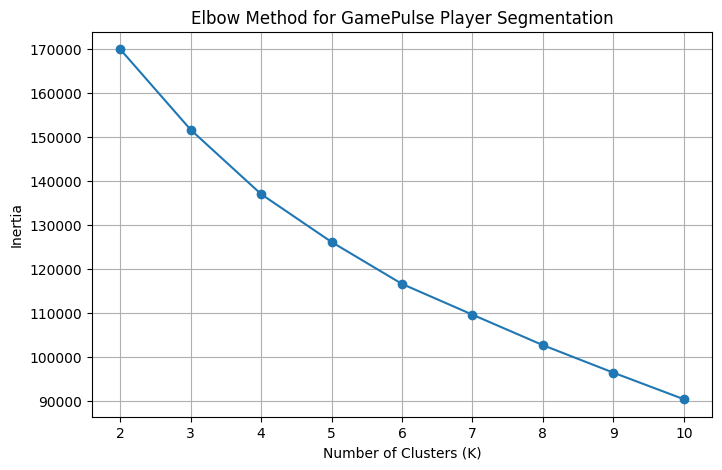

----------------------------------------------------------------------------------------------------
Cluster
0    12773
1    14871
2    12390
Name: count, dtype: int64


In [135]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Test different numbers of clusters
inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for GamePulse Player Segmentation")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()
print("-"*100)


# Train K-means with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Assign each player to a cluster
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to our working dataset
data_clean["Cluster"] = cluster_labels

print(data_clean["Cluster"].value_counts().sort_index())




In [136]:

# Calculate average behaviour for each cluster
cluster_profile = data_clean.groupby("Cluster")[
    clustering_features
].mean().round(2)

print(cluster_profile)


         PlayTimeHours  SessionsPerWeek  AvgSessionDurationMinutes  \
Cluster                                                              
0                18.59             9.20                      92.77   
1                11.59             9.56                      96.28   
2                 5.77             9.65                      95.09   

         PlayerLevel  AchievementsUnlocked  
Cluster                                     
0              33.06                 24.91  
1              79.94                 24.99  
2              30.42                 23.57  


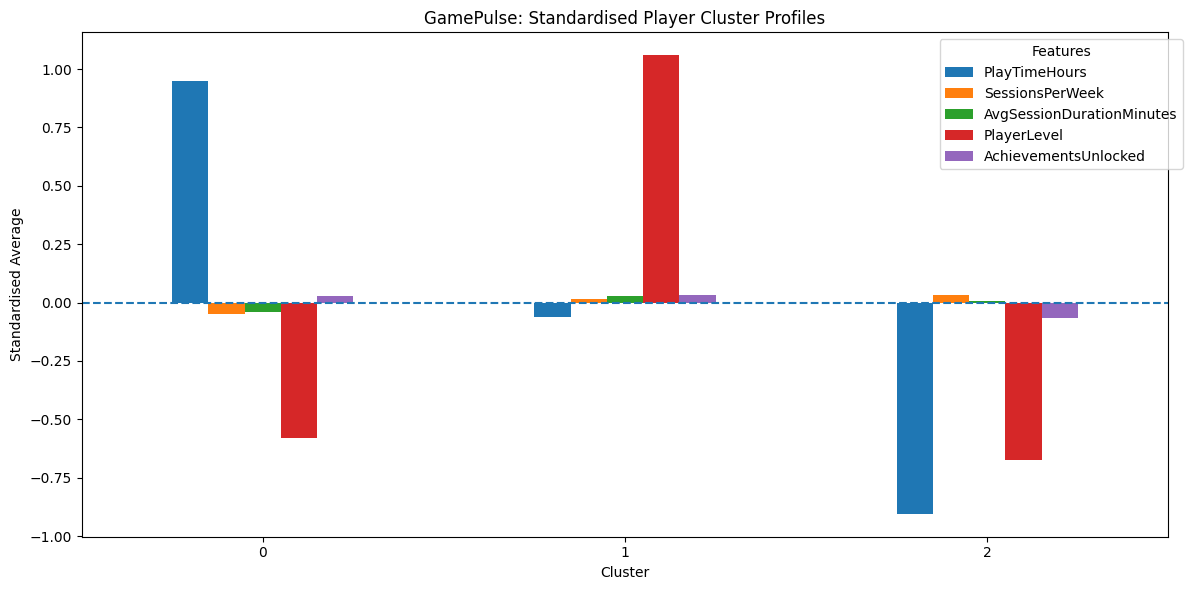

In [137]:

# Standardise the cluster averages for visual comparison
cluster_profile_scaled = pd.DataFrame(
    scaler.transform(cluster_profile),
    index=cluster_profile.index,
    columns=clustering_features
)

cluster_profile_scaled.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("GamePulse: Standardised Player Cluster Profiles")
plt.xlabel("Cluster")
plt.ylabel("Standardised Average")
plt.xticks(rotation=0)
plt.axhline(y=0, linestyle="--")
plt.legend(title="Features", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


6. Anomaly Detection Using Isolation Forest — Identified player records with unusual combinations of gaming characteristics.

In [158]:
#ANAMOLIES

anomaly_features = [
    "PlayTimeHours",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "PlayerLevel",
    "AchievementsUnlocked"
]

X_anomaly = data_clean[anomaly_features].copy()

print("Shape of anomaly dataset:", X_anomaly.shape)

Shape of anomaly dataset: (40034, 5)


In [159]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(
    contamination=0.05,
    random_state=42
)

anomaly_labels = iso_forest.fit_predict(X_anomaly)

data_clean["AnomalyFlag"] = anomaly_labels

print(data_clean["AnomalyFlag"].value_counts())

AnomalyFlag
 1    38032
-1     2002
Name: count, dtype: int64


In [160]:
data_clean["AnomalyScore"] = (
    iso_forest.decision_function(X_anomaly)
)

print(data_clean["AnomalyScore"].describe().round(4))

count    40034.0000
mean         0.0549
std          0.0317
min         -0.0670
25%          0.0333
50%          0.0564
75%          0.0781
max          0.1338
Name: AnomalyScore, dtype: float64


In [161]:
print("Lowest 10 anomaly scores:")

print(
    data_clean.nsmallest(10, "AnomalyScore")[
        anomaly_features + ["AnomalyScore", "AnomalyFlag"]
    ]
)

Lowest 10 anomaly scores:
       PlayTimeHours  SessionsPerWeek  AvgSessionDurationMinutes  PlayerLevel  \
37103       0.577141                0                         20            3   
22801       0.127691               19                         15           25   
17829       0.030321               17                         30           98   
11313      23.401716                1                         15            3   
8673        0.515397                8                         10           97   
22664      23.994079                0                         11            2   
12889       1.744857                0                         13            6   
2100        0.533541               19                         13           37   
23533       0.088443               13                        175           99   
1929        0.203195               19                        156           91   

       AchievementsUnlocked  AnomalyScore  AnomalyFlag  
37103                    

In [163]:
anomaly_summary = data_clean.groupby("AnomalyFlag")[
    anomaly_features
].mean().round(2).T

print(anomaly_summary)

AnomalyFlag                   -1      1
PlayTimeHours              10.35  12.11
SessionsPerWeek            10.05   9.44
AvgSessionDurationMinutes  96.52  94.70
PlayerLevel                53.70  49.44
AchievementsUnlocked       24.19  24.54


In [169]:
anomalies = data_clean[data_clean["AnomalyFlag"] == -1]

print("Total anomaly rows:", len(anomalies))
round(anomalies,2)

Total anomaly rows: 2002


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel,Cluster,AnomalyFlag,AnomalyScore
28,9028,23,Male,Europe,Simulation,3.22,0,Easy,14,57,2,1,Medium,2,-1,-0.00
47,9047,43,Male,USA,Strategy,1.60,0,Medium,3,31,73,49,Low,1,-1,-0.00
53,9053,45,Male,Europe,Simulation,23.70,1,Easy,1,50,95,26,Low,1,-1,-0.00
74,9074,25,Male,Europe,RPG,20.81,1,Easy,19,109,91,48,High,1,-1,-0.01
150,9150,42,Male,Europe,Sports,0.07,0,Hard,18,117,40,0,High,2,-1,-0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39922,48922,26,Female,Europe,Simulation,1.27,0,Medium,0,18,1,28,Low,2,-1,-0.04
39948,48948,16,Female,Asia,RPG,2.34,0,Easy,19,91,15,3,High,2,-1,-0.00
39962,48962,34,Male,USA,Strategy,8.66,1,Medium,17,52,98,49,Medium,1,-1,-0.01
39966,48966,35,Female,USA,Sports,18.69,1,Easy,19,12,72,45,Medium,1,-1,-0.01


7. Predictive Modelling - Compared machine learning models to classify player engagement levels and evaluated their performance.

In [172]:
print(data_clean["EngagementLevel"].value_counts())

print("\nEngagement percentages:")
print(
    (data_clean["EngagementLevel"].value_counts(normalize=True) * 100)
    .round(2)
)

EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64

Engagement percentages:
EngagementLevel
Medium    48.39
High      25.82
Low       25.79
Name: proportion, dtype: float64


In [173]:
target = "EngagementLevel"

excluded_features = [
    "PlayerID",
    "EngagementLevel",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "Cluster",
    "AnomalyFlag",
    "AnomalyScore"
]

X = data_clean.drop(
    columns=excluded_features,
    errors="ignore"
)

y = data_clean[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

X shape: (40034, 9)
y shape: (40034,)

Input features:
['Age', 'Gender', 'Location', 'GameGenre', 'PlayTimeHours', 'InGamePurchases', 'GameDifficulty', 'PlayerLevel', 'AchievementsUnlocked']


In [174]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (32027, 9)
X_test: (8007, 9)
y_train: (32027,)
y_test: (8007,)


In [175]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Gender",
    "Location",
    "GameGenre",
    "GameDifficulty"
]

numerical_features = [
    "Age",
    "PlayTimeHours",
    "InGamePurchases",
    "PlayerLevel",
    "AchievementsUnlocked"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("num", "passthrough", numerical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (32027, 19)
Processed testing shape: (8007, 19)


In [176]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(X_train_processed, y_train)

baseline_predictions = baseline_model.predict(X_test_processed)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Accuracy:", round(baseline_accuracy * 100, 2), "%")

Baseline Accuracy: 48.4 %


In [177]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

logistic_predictions = logistic_model.predict(X_test_processed)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

Logistic Regression Accuracy: 48.4 %

Classification Report:
              precision    recall  f1-score   support

        High       0.00      0.00      0.00      2067
         Low       0.00      0.00      0.00      2065
      Medium       0.48      1.00      0.65      3875

    accuracy                           0.48      8007
   macro avg       0.16      0.33      0.22      8007
weighted avg       0.23      0.48      0.32      8007



In [178]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_predictions = rf_model.predict(X_test_processed)

rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_macro_f1 = f1_score(
    y_test,
    rf_predictions,
    average="macro"
)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Random Forest Macro F1:", round(rf_macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

Random Forest Accuracy: 45.21 %
Random Forest Macro F1: 0.3002

Classification Report:
              precision    recall  f1-score   support

        High       0.26      0.08      0.12      2067
         Low       0.28      0.11      0.16      2065
      Medium       0.49      0.83      0.62      3875

    accuracy                           0.45      8007
   macro avg       0.34      0.34      0.30      8007
weighted avg       0.38      0.45      0.37      8007



In [179]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Target variable
y_full = data_clean["EngagementLevel"]

# Include the two previously excluded features
features_full = [
    "Age",
    "Gender",
    "Location",
    "GameGenre",
    "PlayTimeHours",
    "InGamePurchases",
    "GameDifficulty",
    "PlayerLevel",
    "AchievementsUnlocked",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes"
]

X_full = data_clean[features_full]

categorical_features = [
    "Gender", "Location", "GameGenre", "GameDifficulty"
]

numerical_features = [
    "Age", "PlayTimeHours", "InGamePurchases",
    "PlayerLevel", "AchievementsUnlocked",
    "SessionsPerWeek", "AvgSessionDurationMinutes"
]

# Split the data
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

# Preprocessing
preprocessor_full = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

# Combine preprocessing and model into one pipeline
full_model = Pipeline(steps=[
    ("preprocessor", preprocessor_full),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train and evaluate
full_model.fit(X_train_full, y_train_full)
full_predictions = full_model.predict(X_test_full)

print("Full Model Accuracy:",
      round(accuracy_score(y_test_full, full_predictions) * 100, 2), "%")

print("Full Model Macro F1:",
      round(f1_score(y_test_full, full_predictions, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(
    y_test_full,
    full_predictions,
    zero_division=0
))


Full Model Accuracy: 89.97 %
Full Model Macro F1: 0.8945

Classification Report:
              precision    recall  f1-score   support

        High       0.91      0.85      0.88      2067
         Low       0.91      0.87      0.89      2065
      Medium       0.89      0.94      0.92      3875

    accuracy                           0.90      8007
   macro avg       0.90      0.89      0.89      8007
weighted avg       0.90      0.90      0.90      8007



                           Feature  Importance
19            num__SessionsPerWeek      0.3760
20  num__AvgSessionDurationMinutes      0.3006
15              num__PlayTimeHours      0.0629
17                num__PlayerLevel      0.0603
18       num__AchievementsUnlocked      0.0569
14                        num__Age      0.0494
16            num__InGamePurchases      0.0075
5                cat__Location_USA      0.0073
11        cat__GameDifficulty_Easy      0.0070
3             cat__Location_Europe      0.0068


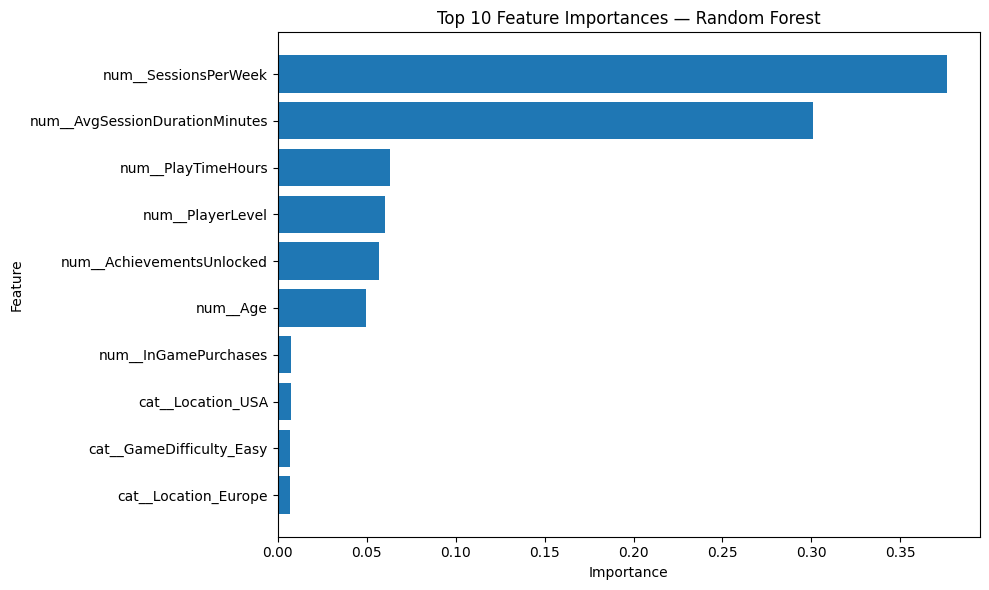

In [180]:

import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = full_model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance from Random Forest
importances = full_model.named_steps["classifier"].feature_importances_

# Create a sorted table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Display the top 10 features
print(feature_importance.head(10).round(4))

# Visualize the top 10 features
top_features = feature_importance.head(10).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()
